In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.layers import Resizing, Rescaling, Input
import matplotlib.pyplot as plt
import numpy as np

In [2]:
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 936s 5us/step


In [3]:
train_images.shape

(50000, 32, 32, 3)

In [4]:
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')

In [5]:
train_labels = to_categorical(train_labels, 10)
test_labels = to_categorical(test_labels, 10)

In [6]:
x_train = train_images[:45000]
y_train = train_labels[:45000]
x_val = train_images[45000:]
y_val = train_labels[45000:]

In [7]:
from tensorflow.keras.applications import MobileNetV2

In [8]:
base_model = MobileNetV2(input_shape=(96, 96, 3),
                         include_top=False,
                         weights='imagenet')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
base_model.trainable = False

In [10]:
tl_model = Sequential([
    Input(shape=(32, 32, 3)),
    Resizing(96, 96),
    Rescaling(1/127.5, offset=-1),
    base_model,
    GlobalAveragePooling2D(), #compresses feature maps, reduces the number of parameters, and creates a compact feature representation for classification.
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

In [11]:
tl_model.compile(optimizer=Adam(learning_rate=0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

In [12]:
tl_h = tl_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 40ms/step - accuracy: 0.7975 - loss: 0.6037 - val_accuracy: 0.8542 - val_loss: 0.4096
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8506 - loss: 0.4328 - val_accuracy: 0.8620 - val_loss: 0.3960
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8690 - loss: 0.3825 - val_accuracy: 0.8696 - val_loss: 0.3774
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8810 - loss: 0.3420 - val_accuracy: 0.8712 - val_loss: 0.3759
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8881 - loss: 0.3157 - val_accuracy: 0.8728 - val_loss: 0.3610
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8969 - loss: 0.2946 - val_accuracy: 0.8754 - val_loss: 0.3676
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9044 - loss: 0.2684 - val_accuracy: 0.8720 - val_loss: 0.3834
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9120 - loss: 0.2495 - val_acc

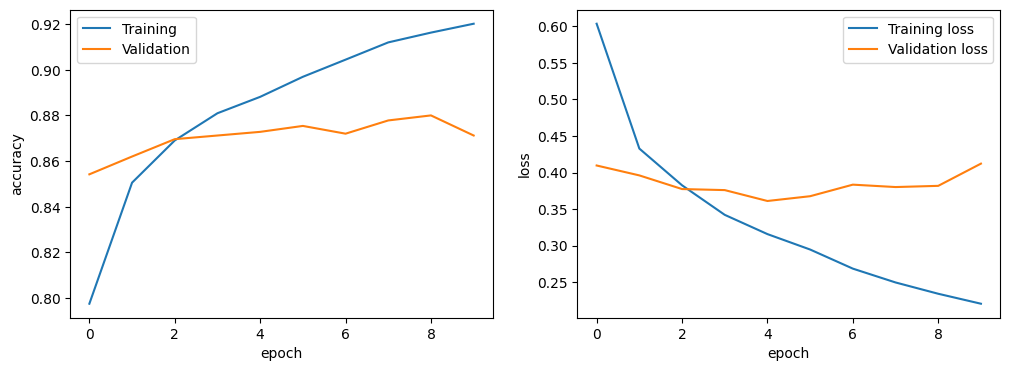

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(tl_h.history['accuracy'], label='Training')
plt.plot(tl_h.history['val_accuracy'], label='Validation')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(tl_h.history['loss'], label='Training loss')
plt.plot(tl_h.history['val_loss'], label='Validation loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [14]:
base_model.trainable = True

In [15]:
len(base_model.layers)

154

In [16]:
fine_tune_at = 100 #MobileNetV2 has 154 layers, the first 100 layers are frozen, while the last 54 layers remain unfrozen.

In [17]:
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

In [18]:
tl_model.compile(optimizer=Adam(learning_rate=0.00001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy'])

In [19]:
hf= tl_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 67s 57ms/step - accuracy: 0.7954 - loss: 0.9025 - val_accuracy: 0.8676 - val_loss: 0.4862
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.8568 - loss: 0.5231 - val_accuracy: 0.8758 - val_loss: 0.4514
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.8760 - loss: 0.4025 - val_accuracy: 0.8790 - val_loss: 0.4258
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.8950 - loss: 0.3182 - val_accuracy: 0.8840 - val_loss: 0.4148
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.9068 - loss: 0.2735 - val_accuracy: 0.8872 - val_loss: 0.4037
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.9183 - loss: 0.2318 - val_accuracy: 0.8914 - val_loss: 0.3938
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.9268 - loss: 0.2061 - val_accuracy: 0.8910 - val_loss: 0.3883
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.9362 - loss: 0.1808 - 

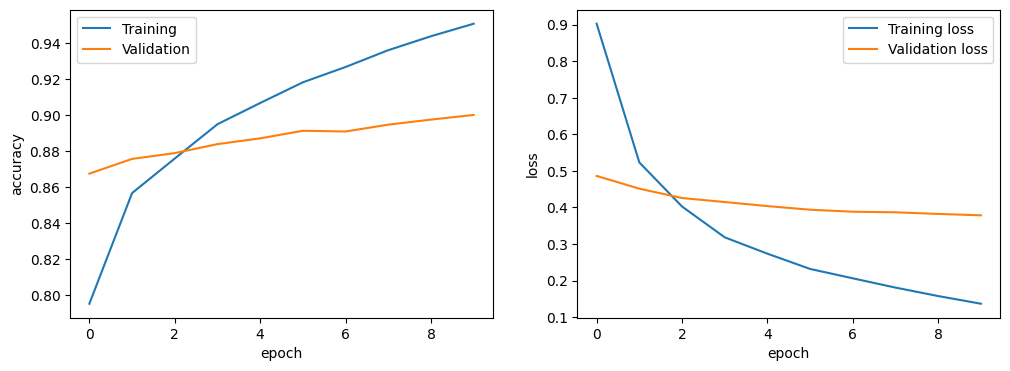

In [20]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hf.history['accuracy'], label='Training')
plt.plot(hf.history['val_accuracy'], label='Validation')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hf.history['loss'], label='Training loss')
plt.plot(hf.history['val_loss'], label='Validation loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [21]:
import numpy as np

In [22]:
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

In [23]:
index = np.random.randint(0, len(test_images))
test_img = test_images[index]

In [24]:
prediction = tl_model.predict(np.expand_dims(test_img, axis=0))
predicted_class = classes[np.argmax(prediction)]
true_class = classes[np.argmax(test_labels[index])]

1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step


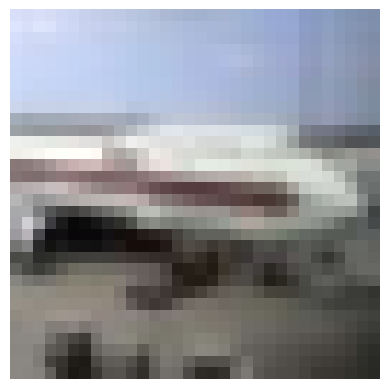

Found


In [25]:
plt.imshow(test_img.astype('uint8'))
plt.axis('off')
plt.show()
if predicted_class == true_class:
    print("Found")
else:
    print("Failed")

In [26]:
test_loss, test_acc = tl_model.evaluate(test_images, test_labels)
test_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 52ms/step - accuracy: 0.8941 - loss: 0.3852


0.89410001039505

313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step


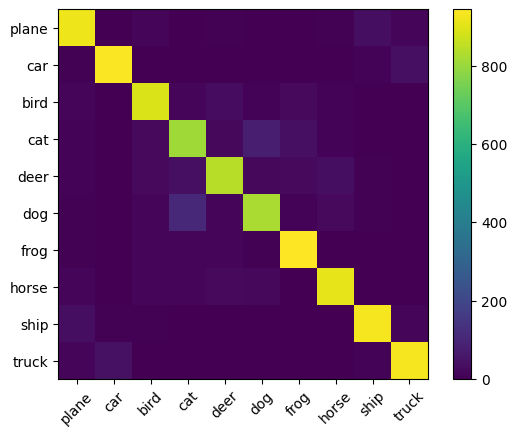

In [27]:
y_pred = np.argmax(tl_model.predict(test_images), axis=1)
y_true = np.argmax(test_labels, axis=1)
cm = tf.math.confusion_matrix(y_true, y_pred)
plt.imshow(cm)
plt.colorbar()
plt.xticks(range(10), classes, rotation=45)
plt.yticks(range(10), classes)
plt.show()